# 01 — Python, NumPy, and your first image

**Level:** Beginner · 60–90 minutes  
**Prerequisites:** No OpenCV experience required; Know how to run a notebook cell with Shift+Enter

## What you will build and learn

- Read a small Python program
- Explain shape, dtype, and image coordinates
- Create, inspect, and change an image using NumPy
- Avoid overflow and accidental edits

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Your first learning habit: predict → run → explain

Before running each code cell, predict one value or visible change. Run it, compare the
result, and write a sentence about why it happened. The setup cell imports `np` (NumPy),
`cv2` (OpenCV), and `plt` (Matplotlib). An **array** is a grid of numbers; an image is
one useful interpretation of that grid. The examples start with tiny grids you can inspect.

If a name is undefined, a previous cell has not run. Use **Restart Kernel and Run All**
after finishing a lesson to make sure your work does not depend on forgotten state.


## Step 1 — Read the Python building blocks

`=` stores a value under a name. `print` displays it. `#` begins a comment; text inside
quotes is a string. Python uses indentation to group instructions. Change `width` below
and predict the new pixel count before you run it.


In [2]:
width = 8
height = 5
number_of_pixels = width * height
label = "my first image"
print(label, "contains", number_of_pixels, "pixels")
print("A width is a", type(width).__name__)


my first image contains 40 pixels
A width is a int


A **list** stores several values. A `for` loop visits them. A **function** packages
reusable instructions; `return` sends a result back. This brightness check is deliberately
simple: a large average is brighter, but it does not tell us what objects an image contains.


In [3]:
sample_brightness = [20, 128, 240]

def describe_brightness(value):
    if value < 80:
        return "dark"
    elif value < 180:
        return "middle"
    return "bright"

for value in sample_brightness:
    print(value, "->", describe_brightness(value))


20 -> dark
128 -> middle
240 -> bright


## Step 2 — Turn numbers into a grayscale image

`np.array` builds an array. `dtype=np.uint8` means unsigned 8-bit integers: whole numbers
from 0 to 255. For a grayscale image, 0 is black and 255 is white. `shape` reports
`(rows, columns)`; `ndim` counts axes; `size` counts stored values. A 3-channel image
has three stored values per pixel, so its `size` is not its pixel count.


In [4]:
tiny = np.array([
    [0, 40, 80, 120],
    [40, 80, 120, 180],
    [80, 120, 180, 255],
], dtype=np.uint8)
print(tiny)
print("shape:", tiny.shape, "axes:", tiny.ndim, "values:", tiny.size, "dtype:", tiny.dtype)
assert tiny.shape == (3, 4)


[[  0  40  80 120]
 [ 40  80 120 180]
 [ 80 120 180 255]]
shape: (3, 4) axes: 2 values: 12 dtype: uint8


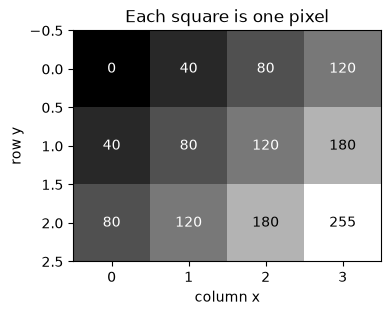

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.imshow(tiny, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for y in range(tiny.shape[0]):
    for x in range(tiny.shape[1]):
        ax.text(x, y, str(tiny[y, x]), ha="center", va="center",
                color="white" if tiny[y, x] < 128 else "black")
ax.set(xlabel="column x", ylabel="row y", title="Each square is one pixel")
plt.show()


The display is enlarged; the image still has only 12 pixels. Fixing `vmin=0` and
`vmax=255` prevents the plot from stretching every image to the same apparent contrast.
Image coordinates start at the **top left**: x increases rightward; y increases downward.

## Step 3 — Locate pixels and crop a region

Python counts from zero. `image[y, x]` addresses one pixel. A slice `start:stop` includes
`start` but excludes `stop`. Read the next slice as rows 0 and 1, columns 1 and 2.


top-left: 0
bottom-right: 255
crop:
 [[ 40  80]
 [ 80 120]]


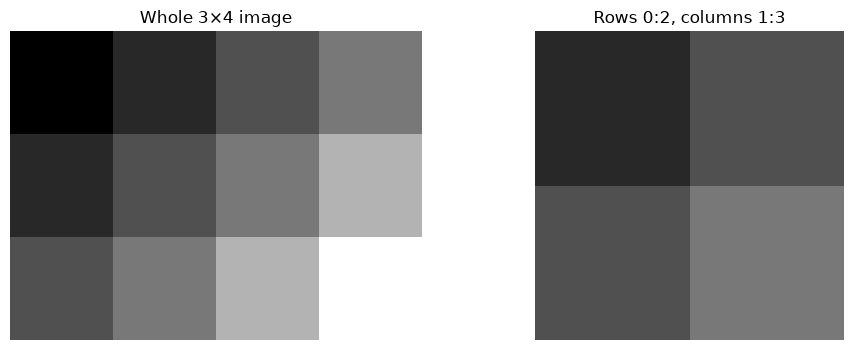

In [6]:
print("top-left:", tiny[0, 0])
print("bottom-right:", tiny[-1, -1])
crop = tiny[0:2, 1:3]
print("crop:\n", crop)
assert crop.shape == (2, 2)
show_images([tiny, crop], ["Whole 3×4 image", "Rows 0:2, columns 1:3"], cols=2)


A NumPy slice usually shares memory with its original: this is called a **view**.
Editing it changes the original. Use `.copy()` for an independent crop. The demonstration
uses a disposable array so that the earlier image stays unchanged.


In [7]:
original = tiny.copy()
view = original[0:2, 0:2]
view[:] = 255
independent_crop = original[0:2, 0:2].copy()
independent_crop[:] = 0
print("Original after editing its view:\n", original)
print("Independent crop:\n", independent_crop)
assert original[0, 0] == 255
assert not np.shares_memory(original, independent_crop)


Original after editing its view:
 [[255 255  80 120]
 [255 255 120 180]
 [ 80 120 180 255]]
Independent crop:
 [[0 0]
 [0 0]]


## Step 4 — Calculate safely with pixels

An 8-bit number has limited storage. Ordinary NumPy `uint8` addition wraps around after
255; `cv2.add` saturates at 255. For general arithmetic, convert to a wider type,
calculate, **clip** to the allowed range, then convert back. `astype` changes the data
type; `np.clip(a, 0, 255)` bounds every value. Never rely on overflow to brighten a photo.


In [8]:
values = np.array([[10, 230, 250]], dtype=np.uint8)
increase = np.full_like(values, 30)
wrapped = values + increase
saturated = cv2.add(values, increase)
safe = np.clip(values.astype(np.int16) + 30, 0, 255).astype(np.uint8)
print("original:", values)
print("NumPy uint8 addition:", wrapped)
print("OpenCV saturated addition:", saturated)
print("wider arithmetic then clipping:", safe)
assert np.array_equal(safe, saturated)


original: [[ 10 230 250]]
NumPy uint8 addition: [[40  4 24]]
OpenCV saturated addition: [[ 40 255 255]]
wider arithmetic then clipping: [[ 40 255 255]]


**Vectorization** means applying an operation to a whole array at once. It is concise
and lets NumPy do the repeated work. `np.linspace` makes evenly spaced values, `np.tile`
repeats them into rows, and `np.mean` calculates their average. A Boolean comparison
such as `gradient > 180` creates a grid of `True`/`False` values.


Mean brightness: 127.5
Fraction brighter than 180: 0.29296875


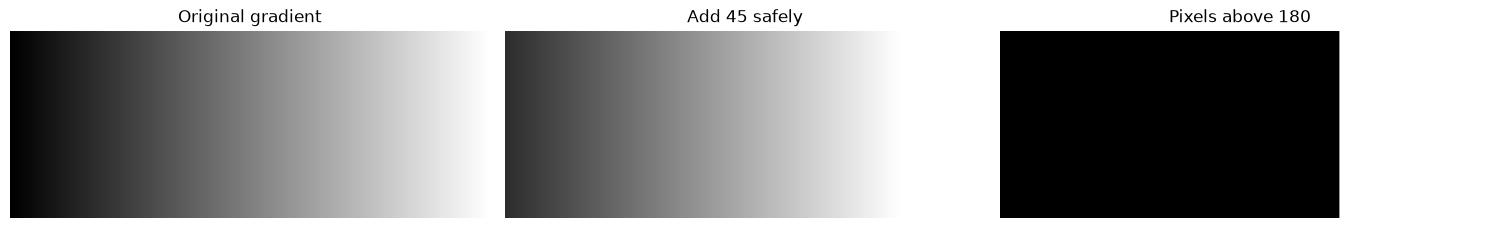

In [9]:
gradient = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (100, 1))
brighter = np.clip(gradient.astype(np.int16) + 45, 0, 255).astype(np.uint8)
bright_pixels = gradient > 180
print("Mean brightness:", float(gradient.mean()))
print("Fraction brighter than 180:", float(bright_pixels.mean()))
show_images([gradient, brighter, bright_pixels.astype(np.uint8) * 255],
            ["Original gradient", "Add 45 safely", "Pixels above 180"])


## Step 5 — Add color channels

OpenCV's usual 3-channel image order is **B, G, R**: blue, green, red. A color array
has shape `(height, width, 3)`. `np.zeros` creates a black canvas. Assigning a 3-number
tuple to a region gives every pixel in that region the same color.

Our `show_images` helper converts BGR to RGB for Matplotlib. Keep your working image
in BGR; convert only when passing it directly to `plt.imshow`.


shape: (140, 300, 3) pixels: 42000
One red pixel, as BGR: [  0   0 255]


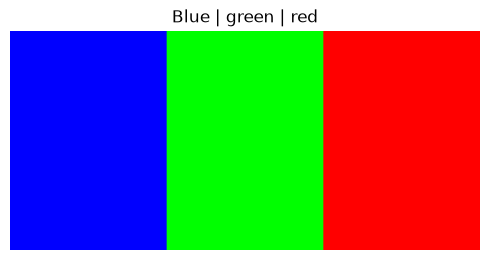

In [10]:
color = np.zeros((140, 300, 3), dtype=np.uint8)
color[:, 0:100] = (255, 0, 0)       # Blue in BGR
color[:, 100:200] = (0, 255, 0)     # Green
color[:, 200:300] = (0, 0, 255)     # Red
print("shape:", color.shape, "pixels:", color.shape[0] * color.shape[1])
print("One red pixel, as BGR:", color[50, 250])
show_images([color], ["Blue | green | red"], cols=1)


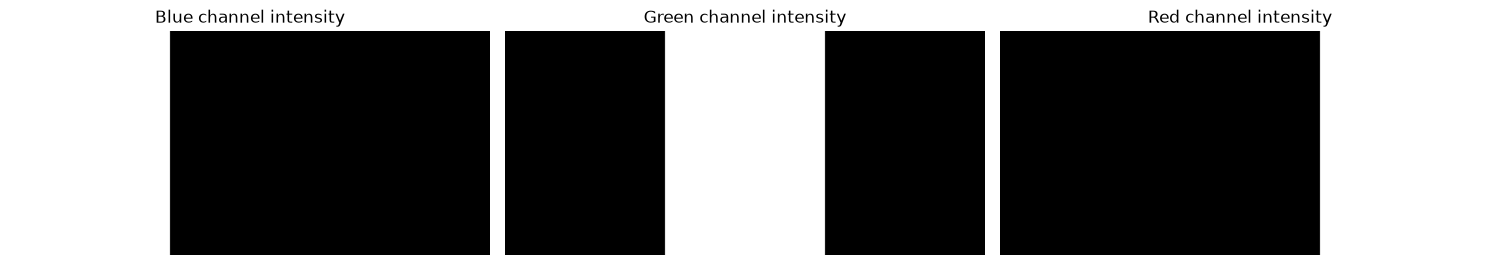

In [11]:
blue_channel = color[:, :, 0]
green_channel = color[:, :, 1]
red_channel = color[:, :, 2]
show_images([blue_channel, green_channel, red_channel],
            ["Blue channel intensity", "Green channel intensity", "Red channel intensity"])
assert blue_channel.ndim == 2


**Expected observation:** in a channel image, white means that channel is strong.
A red object appears bright in the red channel even though this channel plot is grayscale.

### Parameter experiment

Change `brightness_offset` to -60, 0, and 90. Predict what will happen to the black
background and already-bright stripes. Clipping loses differences among pixels that
all become 0 or 255; it is not reversible.


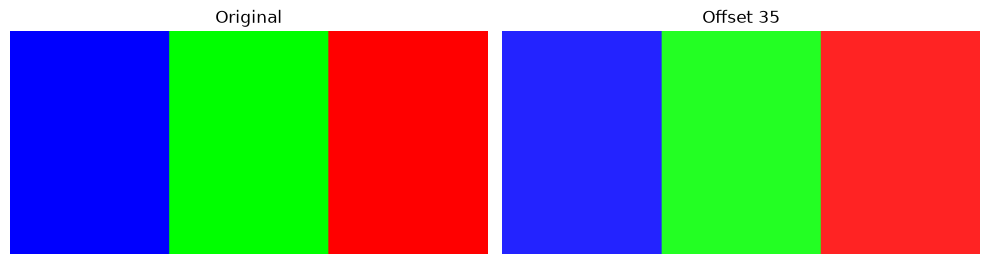

Values at either endpoint: 0.3333333333333333


In [12]:
brightness_offset = 35     # Experiment: -60, 0, 90
adjusted_color = np.clip(color.astype(np.int16) + brightness_offset, 0, 255).astype(np.uint8)
show_images([color, adjusted_color], ["Original", f"Offset {brightness_offset}"], cols=2)
print("Values at either endpoint:", np.mean((adjusted_color == 0) | (adjusted_color == 255)))


## Step 6 — Mini-project: an image inspection card

Create a reusable function that reports an image's dimensions and brightness. Convert
BGR to grayscale with `cv2.cvtColor` and `cv2.COLOR_BGR2GRAY`; this uses weighted color
contributions, so green and blue do not contribute equally. For this project, the function
accepts the grayscale or BGR `uint8` images used in the course.


{'height': 420, 'width': 640, 'channels': 3, 'dtype': 'uint8', 'mean_gray': 181.61, 'min_gray': 30, 'max_gray': 245}


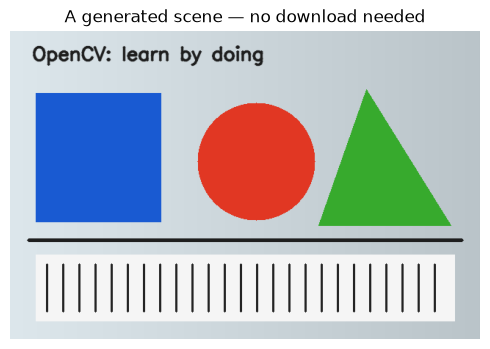

In [13]:
def inspect_image(image):
    if image is None or image.size == 0:
        raise ValueError("Pass a non-empty image.")
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    return {
        "height": int(image.shape[0]),
        "width": int(image.shape[1]),
        "channels": 1 if image.ndim == 2 else int(image.shape[2]),
        "dtype": str(image.dtype),
        "mean_gray": round(float(gray.mean()), 2),
        "min_gray": int(gray.min()),
        "max_gray": int(gray.max()),
    }

scene = make_scene()
report = inspect_image(scene)
print(report)
show_images([scene], ["A generated scene — no download needed"], cols=1)
assert report["width"] == scene.shape[1]
assert 0 <= report["mean_gray"] <= 255


### Try it yourself before opening the solutions

1. Make a 120-row, 200-column grayscale canvas filled with 60. Set its central
   rectangle (rows 30:90, columns 50:150) to 220. What fraction is bright?
2. Extract an independent copy of that central rectangle and make it black. Prove
   that the original central rectangle remains bright.
3. Write `safe_brighten(image, offset)` and test a negative offset.

Write your attempt in the next cell, or insert your own cells. The placeholder is valid
Python so **Run All** works before you solve the exercises.


In [14]:
# Your practice area. Example starting point:
practice_canvas = np.full((120, 200), 60, dtype=np.uint8)
# Add your own slicing and arithmetic here.


### Worked solutions — compare the reasoning, not just the picture

The rectangle covers `60 × 100` pixels out of `120 × 200`, so the bright fraction
is 0.25. Casting before addition makes both positive and negative offsets safe.


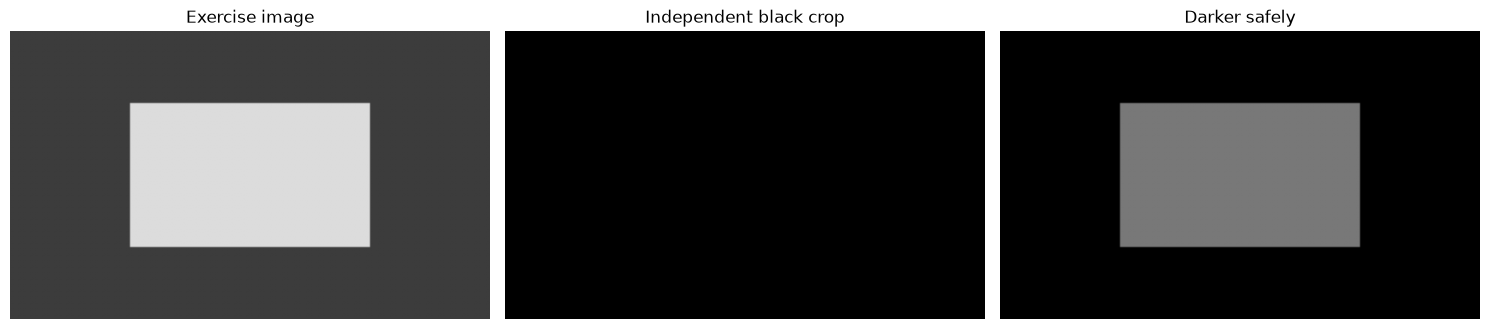

In [15]:
answer = np.full((120, 200), 60, dtype=np.uint8)
answer[30:90, 50:150] = 220
answer_crop = answer[30:90, 50:150].copy()
answer_crop[:] = 0

def safe_brighten(image, offset):
    return np.clip(image.astype(np.float32) + offset, 0, 255).astype(np.uint8)

assert np.isclose((answer > 180).mean(), 0.25)
assert np.all(answer[30:90, 50:150] == 220)
assert safe_brighten(answer, -100).min() == 0
show_images([answer, answer_crop, safe_brighten(answer, -100)],
            ["Exercise image", "Independent black crop", "Darker safely"])


### Reflection and debugging checklist

- Why does `(100, 200, 3)` describe 20,000 pixels rather than 60,000 pixels?
- Explain the difference between drawing coordinates `(x, y)` and array indexing `[y, x]`.
- Why can adding brightness make a `uint8` value darker with plain NumPy addition?
- When should you use `.copy()`? What evidence would show that two arrays share memory?

**You are ready for lesson 02 when** you can create a color image, crop it, print its
shape and dtype, and modify it safely without copying the solution.

Official reference: [OpenCV — basic image operations](https://docs.opencv.org/4.x/d3/df2/tutorial_py_basic_ops.html).
